**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053.10 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Profesora titular: Dra. Grettel Barceló

Profesor tutor: Mtro. Roberto Antonio Guevara González

**Semana 5**  
Preprocesamiento de datos

---

* **NOMBRE:** Alejandro Santiago Baca Eyssautier
* **MATRÍCULA:** A01656580

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [324]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.impute import SimpleImputer

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [325]:
ruta_datos = Path('heart_disease.csv')
cardio_df = pd.read_csv(ruta_datos).set_index('id')

cardio_df.info()

tipos_iniciales = pd.Series({
    'columnas_numéricas': cardio_df.select_dtypes(include='number').shape[1],
    'columnas_de_texto': cardio_df.select_dtypes(include='object').shape[1]
}, name='cantidad')

display(tipos_iniciales.to_frame())
display(cardio_df.nunique(dropna=False).to_frame('valores_únicos'))

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


,cantidad
columnas_numéricas,7
columnas_de_texto,8


,valores_únicos
age,50
sex,2
origin,4
cp,4
trestbps,61
chol,217
fbs,3
restecg,3
thalch,120
exang,3


**Análisis.** Después de establecer `id` como índice, el dataframe contiene **918 registros y 15 variables**. Pandas identifica inicialmente **7 columnas numéricas** y **8 columnas de tipo `object`**. La inspección de valores únicos muestra que `ca` y `num` son numéricas con muy pocos niveles, por lo que deben revisarse como posibles variables categóricas codificadas.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [326]:
numericas_pocos_valores = pd.DataFrame({
    'tipo_original': cardio_df.select_dtypes(include='number').dtypes.astype(str),
    'valores_únicos': cardio_df.select_dtypes(include='number').nunique(dropna=True)
}).sort_values('valores_únicos')

display(numericas_pocos_valores)

display(cardio_df['ca'].value_counts(dropna=False).to_frame('valores_únicos'))
display(cardio_df['num'].value_counts(dropna=False).to_frame('valores_únicos'))

tipo_ca = pd.CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
tipo_num = pd.CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

cardio_df['ca'] = cardio_df['ca'].astype(tipo_ca)
cardio_df['num'] = cardio_df['num'].astype(tipo_num)

display(cardio_df[['ca', 'num']].dtypes.to_frame('tipo_convertido'))

,tipo_original,valores_únicos
ca,float64,4
num,int64,5
age,int64,50
oldpeak,float64,53
trestbps,float64,60
thalch,float64,119
chol,float64,216


,valores_únicos
ca,
NaN,609
0.0000,181
1.0000,67
2.0000,41
3.0000,20


,valores_únicos
num,
0,411
1,263
2,109
3,107
4,28


,tipo_convertido
ca,category
num,category


**Análisis.** `ca` representa cuatro niveles ordenados del número de vasos principales observados por fluoroscopía y `num` codifica la severidad de enfermedad de 0 a 4. Ambas variables se convierten a categorías ordinales porque sus números representan niveles clínicos ordenados, no magnitudes continuas. Las demás variables numéricas conservan su naturaleza cuantitativa.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [327]:
num_cols_iniciales = cardio_df.select_dtypes(include='number').columns.tolist()
cat_cols_iniciales = cardio_df.select_dtypes(include=['object', 'category']).columns.tolist()

estadisticas_numericas = cardio_df[num_cols_iniciales].describe().T
estadisticas_numericas['sesgo'] = cardio_df[num_cols_iniciales].skew()
estadisticas_numericas['curtosis'] = cardio_df[num_cols_iniciales].kurtosis()

display(estadisticas_numericas)
display(cardio_df[cat_cols_iniciales].describe().T)

frecuencias = []
for variable in cat_cols_iniciales:
    tabla = cardio_df[variable].value_counts(dropna=False).rename_axis('categoría').reset_index(name='frecuencia')
    tabla['porcentaje'] = tabla['frecuencia'].div(len(cardio_df)).mul(100)
    tabla.insert(0, 'variable', variable)
    frecuencias.append(tabla)

display(pd.concat(frecuencias, ignore_index=True))

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0000,53.5305,9.4128,28.0000,47.0000,54.0000,60.0000,77.0000,-0.1937,-0.3825
trestbps,859.0000,132.2945,18.5359,80.0000,120.0000,130.0000,140.0000,200.0000,0.6304,0.6330
chol,888.0000,242.1892,53.4248,85.0000,216.0000,223.0000,268.0000,603.0000,1.6407,6.5738
thalch,863.0000,137.5284,25.9502,60.0000,120.0000,140.0000,157.0000,202.0000,-0.2093,-0.4839
oldpeak,856.0000,0.8806,1.0918,-2.6000,0.0000,0.5000,1.5000,6.2000,1.0380,1.1198


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0000,4.0000,0.0000,181.0000
thal,434,3,normal,196
num,918,5,0,411


,variable,categoría,frecuencia,porcentaje
0,sex,Male,724,78.8671
1,sex,Female,194,21.1329
2,origin,Cleveland,304,33.1155
3,origin,Hungary,292,31.8083
4,origin,VA Long Beach,200,21.7865
5,origin,Switzerland,122,13.2898
6,cp,asymptomatic,495,53.9216
7,cp,non-anginal,204,22.2222
8,cp,atypical angina,174,18.9542
9,cp,typical angina,45,4.9020


**Análisis.** Las variables numéricas presentan escalas y dispersiones muy distintas. `oldpeak` muestra sesgo positivo, mientras que `chol` contiene valores altos alejados del centro. Entre las categóricas, predominan pacientes masculinos, registros de Cleveland y dolor torácico asintomático. Las tablas de frecuencia también hacen visibles los valores ausentes antes de decidir su tratamiento.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

,porcentaje_faltante
ca,66.3399
thal,52.7233
slope,33.5512
fbs,9.6950
oldpeak,6.7538
trestbps,6.4270
thalch,5.9913
exang,5.9913
chol,3.2680
age,0.0000


,columnas_eliminadas
0,ca
1,thal
2,slope


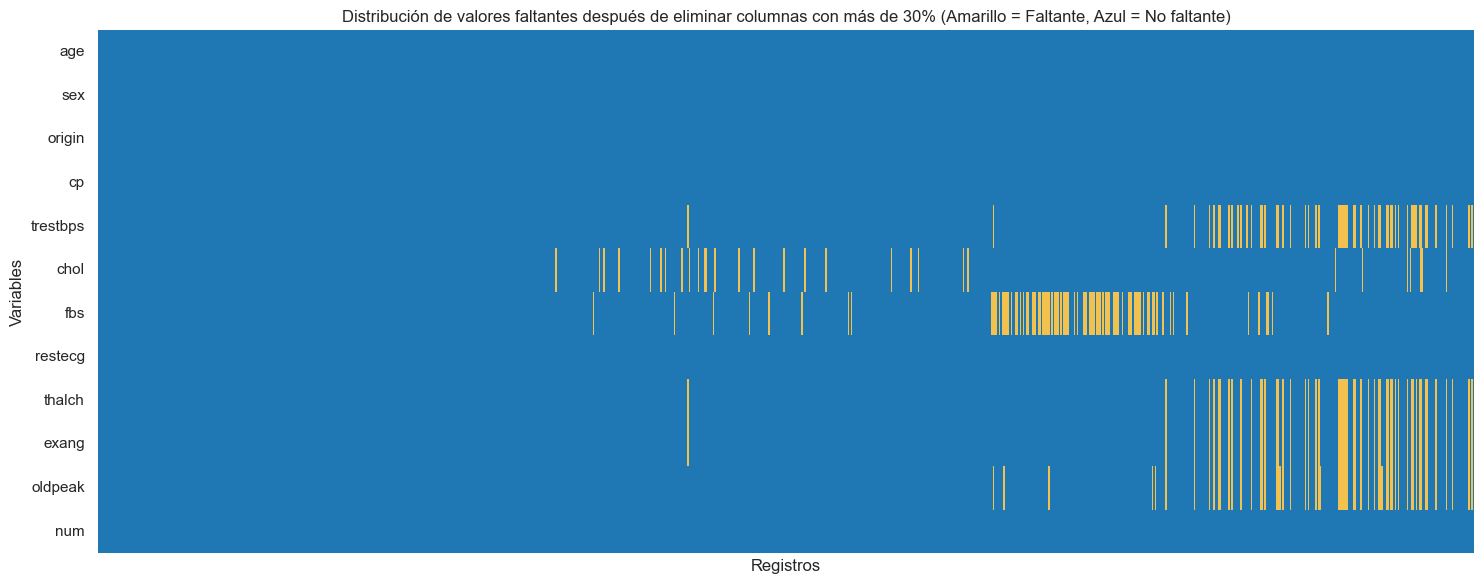

,trestbps,chol,fbs,thalch,exang,oldpeak
trestbps,59,3,1,55,55,55
chol,3,30,0,3,3,3
fbs,1,0,89,0,0,4
thalch,55,3,0,55,55,54
exang,55,3,0,55,55,54
oldpeak,55,3,4,54,54,62


,trestbps,chol,fbs,thalch,exang,oldpeak,registros
0,False,False,False,False,False,False,740
1,False,False,True,False,False,False,85
2,True,False,False,True,True,True,51
3,False,True,False,False,False,False,27
4,False,False,False,False,False,True,4
5,False,False,True,False,False,True,3
6,True,False,False,False,False,False,3
7,True,True,False,True,True,True,3
8,True,False,False,True,True,False,1
9,True,False,True,False,False,True,1


thalch,False,True,All
origin,,,
Cleveland,304,0,304
Hungary,291,1,292
Switzerland,121,1,122
VA Long Beach,147,53,200
All,863,55,918


In [328]:
porcentaje_faltantes = cardio_df.isna().mean().mul(100).sort_values(ascending=False).round(4)
display(porcentaje_faltantes.to_frame('porcentaje_faltante'))

columnas_eliminadas = porcentaje_faltantes[porcentaje_faltantes > 30].index.tolist()
cardio_df = cardio_df.drop(columns=columnas_eliminadas)

display(pd.DataFrame({'columnas_eliminadas': columnas_eliminadas}))

plt.figure(figsize=(15, 6))
sns.heatmap(cardio_df.isna().T, cmap=['#1f77b4', '#f2c14e'], cbar=False, yticklabels=True, xticklabels=False)
plt.title('Distribución de valores faltantes después de eliminar columnas con más de 30% (Amarillo = Faltante, Azul = No faltante)')
plt.xlabel('Registros')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

columnas_con_faltantes = cardio_df.columns[cardio_df.isna().any()].tolist()
matriz_faltantes = cardio_df[columnas_con_faltantes].isna().astype(int)
concurrencia = matriz_faltantes.T.dot(matriz_faltantes)
patrones = cardio_df[columnas_con_faltantes].isna().value_counts().head(10).rename('registros').reset_index()
origen_thalch = pd.crosstab(cardio_df['origin'], cardio_df['thalch'].isna(), margins=True)

display(concurrencia)
display(patrones)
display(origen_thalch)

**Análisis.** Se eliminan `slope`, `ca` y `thal` porque superan 30% de ausencia. El patrón dominante restante involucra `trestbps`, `thalch`, `exang` y `oldpeak`: `thalch` y `exang` faltan simultáneamente en los 55 casos, `trestbps` coincide en esos mismos 55 y `oldpeak` en 54. La concurrencia tiene sentido clínico porque `thalch`, `exang` y `oldpeak` se obtienen durante una prueba de esfuerzo; si el estudio no se realizó o quedó incompleto, las tres mediciones pueden faltar juntas. `trestbps` es una medición basal diferente, pero su ausencia en el mismo bloque sugiere registros clínicos incompletos o una diferencia de captura entre centros. Esto se refuerza porque **53 de los 55 faltantes de `thalch` proceden de VA Long Beach**.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

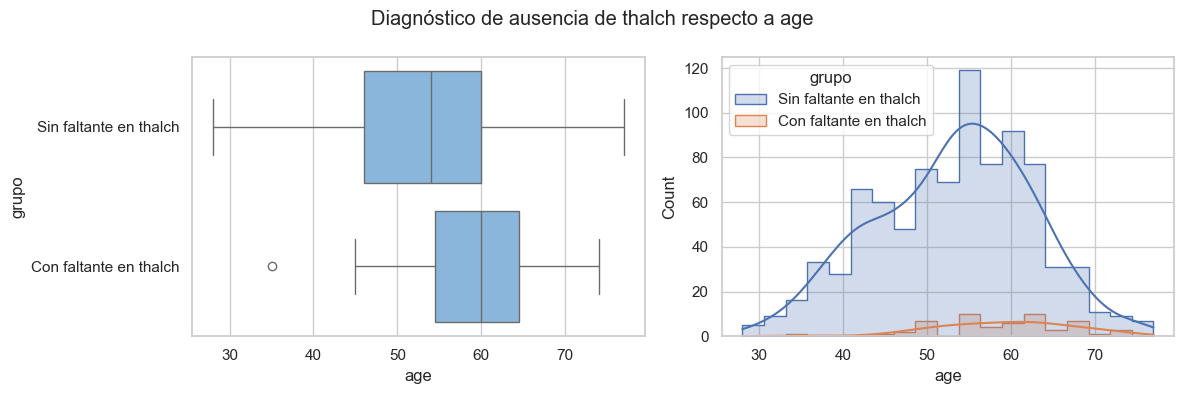

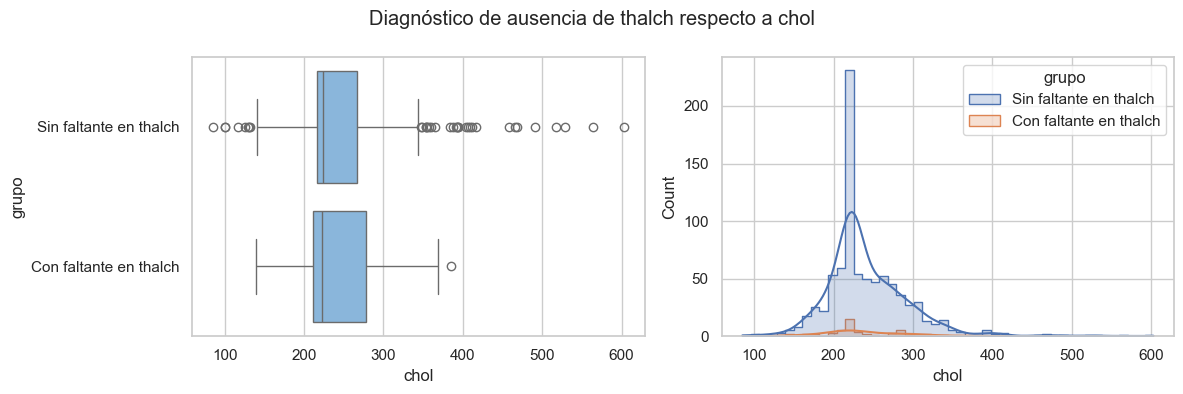

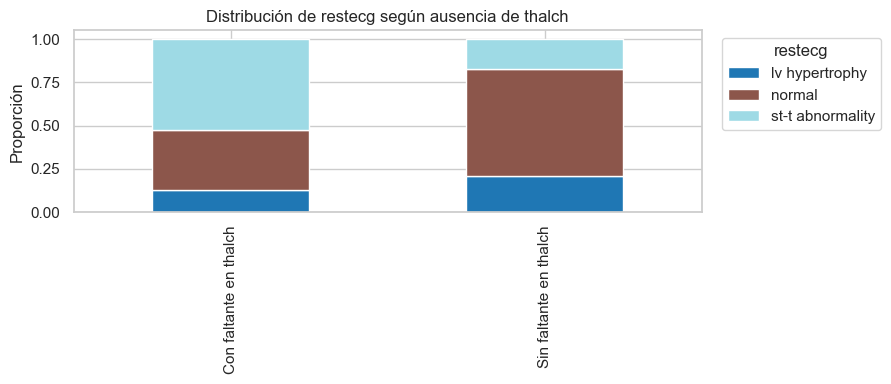

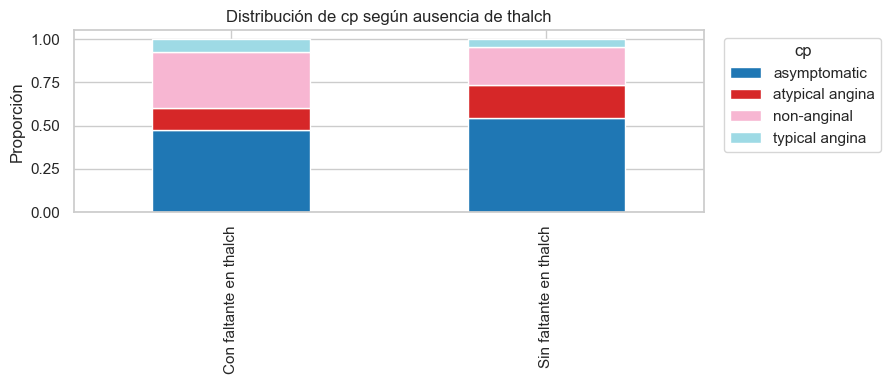

,variable,prueba,media_con_faltante,media_sin_faltante,estadístico,p_value
0,age,t de Welch,59.4182,53.1553,5.6400,0.0000
1,chol,t de Welch,239.5769,242.3517,-0.3731,0.7105


,variable,prueba,estadístico,p_value
0,restecg,chi-cuadrada,41.1717,0.0000
1,cp,chi-cuadrada,5.2527,0.1542


In [329]:
def diagnostico_numerico(df, variable, indicador):
    etiquetas = indicador.map({True: 'Con faltante en thalch', False: 'Sin faltante en thalch'})
    datos = pd.DataFrame({variable: df[variable], 'grupo': etiquetas})

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(data=datos, x=variable, y='grupo', ax=axes[0], color='#7db7e8')
    sns.histplot(data=datos, x=variable, hue='grupo', kde=True, element='step', common_norm=False, ax=axes[1])
    fig.suptitle(f'Diagnóstico de ausencia de thalch respecto a {variable}')
    plt.tight_layout()
    plt.show()

    grupo_faltante = df.loc[indicador, variable].dropna()
    grupo_completo = df.loc[~indicador, variable].dropna()
    prueba = ttest_ind(grupo_faltante, grupo_completo, equal_var=False, nan_policy='omit')

    return {
        'variable': variable,
        'prueba': 't de Welch',
        'media_con_faltante': grupo_faltante.mean(),
        'media_sin_faltante': grupo_completo.mean(),
        'estadístico': prueba.statistic,
        'p_value': prueba.pvalue
    }


def diagnostico_categorico(df, variable, indicador):
    etiquetas = indicador.map({True: 'Con faltante en thalch', False: 'Sin faltante en thalch'})
    tabla_conteos = pd.crosstab(etiquetas, df[variable])
    tabla_proporciones = pd.crosstab(etiquetas, df[variable], normalize='index')

    tabla_proporciones.plot(kind='bar', stacked=True, figsize=(9, 4), colormap='tab20')
    plt.title(f'Distribución de {variable} según ausencia de thalch')
    plt.ylabel('Proporción')
    plt.xlabel('')
    plt.legend(title=variable, bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    prueba = chi2_contingency(tabla_conteos)

    return {
        'variable': variable,
        'prueba': 'chi-cuadrada',
        'estadístico': prueba.statistic,
        'p_value': prueba.pvalue
    }

thalch_faltante = cardio_df['thalch'].isna()

resultados_numericos = pd.DataFrame([
    diagnostico_numerico(cardio_df, 'age', thalch_faltante),
    diagnostico_numerico(cardio_df, 'chol', thalch_faltante)
])

resultados_categoricos = pd.DataFrame([
    diagnostico_categorico(cardio_df, 'restecg', thalch_faltante),
    diagnostico_categorico(cardio_df, 'cp', thalch_faltante)
])

display(resultados_numericos)
display(resultados_categoricos)

**Conclusión.** La edad difiere significativamente entre los grupos: los pacientes con `thalch` faltante tienen una media aproximada de **59.42 años**, frente a **53.16 años** en el grupo completo (`p ≈ 4.12×10⁻⁷`). `restecg` también presenta una asociación significativa (`p ≈ 1.15×10⁻⁹`), con una proporción mucho mayor de anomalías ST-T entre los registros sin `thalch`. En cambio, `chol` (`p ≈ 0.710`) y `cp` (`p ≈ 0.154`) no muestran diferencias significativas. Por lo tanto, la ausencia de `thalch` no es MCAR: depende de variables observadas como edad y `restecg`, por lo que el mecanismo se clasifica como **MAR**.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

,faltantes
chol,30
fbs,89


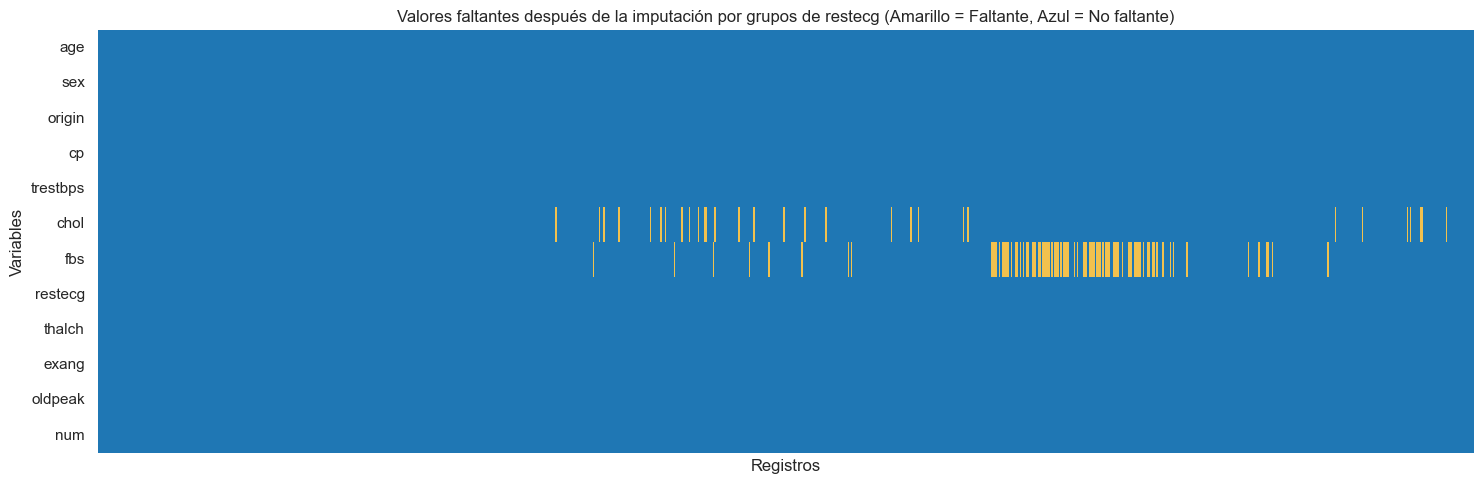

In [330]:
variables_patron_similar = ['trestbps', 'thalch', 'exang', 'oldpeak']

for variable in ['trestbps', 'thalch', 'oldpeak']:
    cardio_df[variable] = cardio_df.groupby('restecg', observed=False)[variable].transform(
        lambda grupo: grupo.fillna(grupo.median())
    )

modas_exang = cardio_df.groupby('restecg', observed=False)['exang'].agg(
    lambda grupo: grupo.mode(dropna=True).iloc[0]
)
relleno_exang = cardio_df['restecg'].map(modas_exang)
cardio_df['exang'] = cardio_df['exang'].where(cardio_df['exang'].notna(), relleno_exang)

faltantes_despues_grupos = cardio_df.isna().sum()
display(faltantes_despues_grupos[faltantes_despues_grupos > 0].to_frame('faltantes'))

plt.figure(figsize=(15, 5))
sns.heatmap(cardio_df.isna().T, cmap=['#1f77b4', '#f2c14e'], cbar=False, yticklabels=True, xticklabels=False)
plt.title('Valores faltantes después de la imputación por grupos de restecg (Amarillo = Faltante, Azul = No faltante)')
plt.xlabel('Registros')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

**Análisis.** Se imputan por grupos de `restecg` las variables con el patrón concurrente: `trestbps`, `thalch` y `oldpeak` mediante la mediana, y `exang` mediante la moda. La mediana es robusta frente a valores extremos y la moda es apropiada para una variable binaria. El segundo mapa de calor confirma que esas cuatro variables ya no presentan valores faltantes; únicamente permanecen ausencias en `chol` y `fbs`.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


,faltantes
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


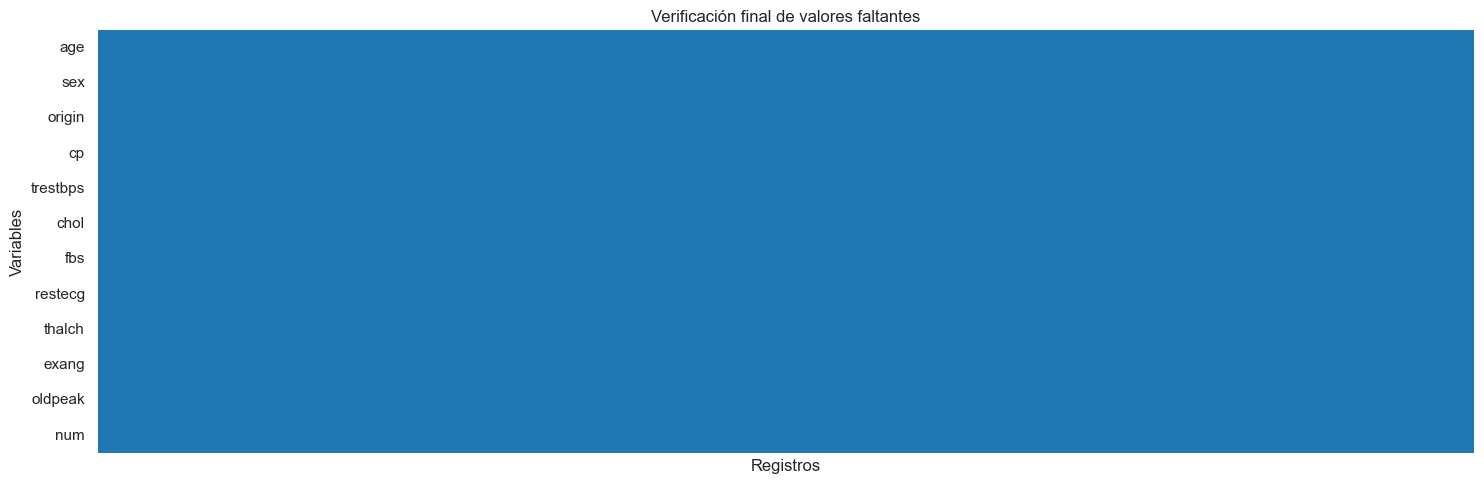

In [331]:
imputador_colesterol = SimpleImputer(strategy='median')
imputador_fbs = SimpleImputer(strategy='most_frequent')

cardio_df[['chol']] = imputador_colesterol.fit_transform(cardio_df[['chol']])
cardio_df[['fbs']] = imputador_fbs.fit_transform(cardio_df[['fbs']])

faltantes_finales = cardio_df.isna().sum().to_frame('faltantes')
display(faltantes_finales)

plt.figure(figsize=(15, 5))
sns.heatmap(cardio_df.isna().T, cmap=['#1f77b4', '#f2c14e'], cbar=False, yticklabels=True, xticklabels=False)
plt.title('Verificación final de valores faltantes')
plt.xlabel('Registros')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

**Justificación.** `chol` se imputa con la **mediana** porque es numérica y contiene una cola derecha con valores extremos, por lo que la media sería sensible a observaciones muy altas. `fbs` se imputa con **most_frequent** porque es binaria y la categoría modal conserva una codificación válida. Después de esta etapa no quedan valores faltantes en el dataframe.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

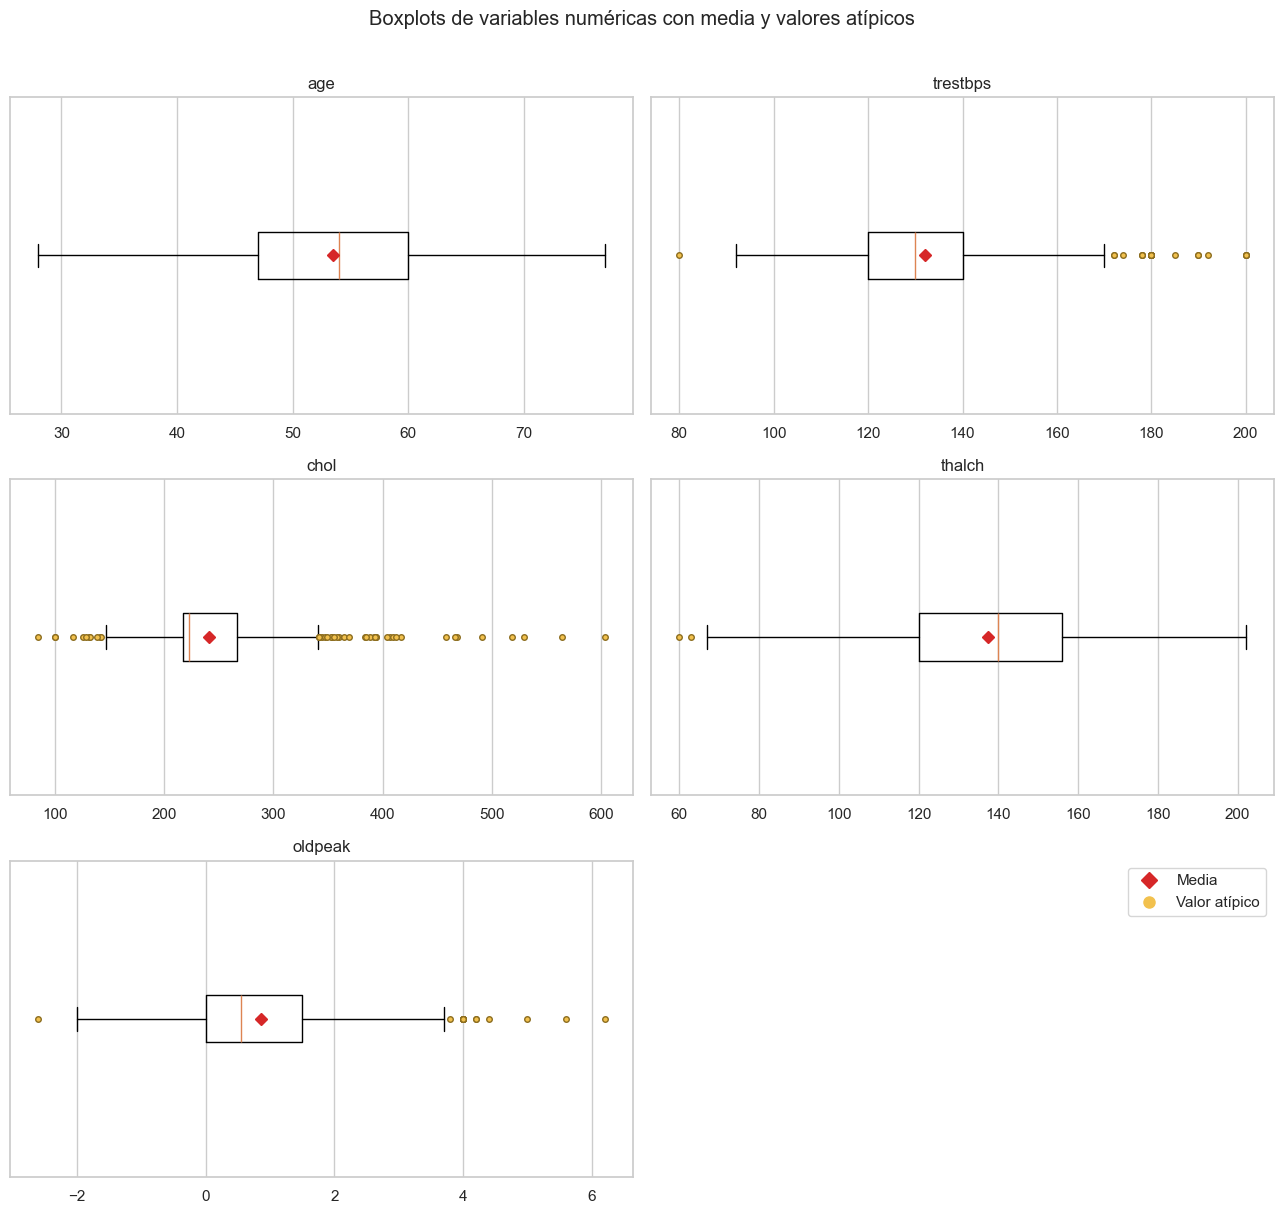

,variable,cantidad_atípicos,valores_atípicos
0,age,0,[]
1,trestbps,27,"[80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178...."
2,chol,44,"[85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131...."
3,thalch,2,"[60.0, 63.0]"
4,oldpeak,16,"[-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0,..."


In [332]:
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
axes = axes.flatten()
valores_atipicos_graficos = {}

for eje, variable in zip(axes, num_cols):
    resultado = eje.boxplot(
        cardio_df[variable].dropna(),
        vert=False,
        showmeans=True,
        meanprops={'marker': 'D', 'markerfacecolor': '#d62728', 'markeredgecolor': '#d62728'},
        flierprops={'marker': 'o', 'markerfacecolor': '#f2c14e', 'markeredgecolor': '#8c6d1f', 'markersize': 4}
    )
    eje.set_title(variable)
    eje.set_yticks([])
    valores_atipicos_graficos[variable] = sorted(resultado['fliers'][0].get_xdata().tolist())

for eje in axes[len(num_cols):]:
    eje.axis('off')

plt.suptitle('Boxplots de variables numéricas con media y valores atípicos', y=1.01)
plt.tight_layout()
plt.legend(handles=[plt.Line2D([0], [0], color='#d62728', marker='D', linestyle='', markersize=8, label='Media'),
                    plt.Line2D([0], [0], color='#f2c14e', marker='o', linestyle='', markersize=8, label='Valor atípico')])
plt.show()

resumen_atipicos = pd.DataFrame({
    'variable': list(valores_atipicos_graficos.keys()),
    'cantidad_atípicos': [len(valores_atipicos_graficos[v]) for v in valores_atipicos_graficos],
    'valores_atípicos': [valores_atipicos_graficos[v] for v in valores_atipicos_graficos]
})

display(resumen_atipicos)

**Análisis.** `age` no presenta atípicos con la regla gráfica de 1.5 IQR. `trestbps` contiene **27**, `chol` **44**, `thalch` **2** y `oldpeak` **16**. La presencia de valores extremos no implica automáticamente un error: en variables clínicas pueden corresponder a pacientes de alto riesgo. Por ello, la eliminación posterior se limita a `trestbps`, tal como solicita el ejercicio.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [333]:
q1_trestbps = cardio_df['trestbps'].quantile(0.25)
q3_trestbps = cardio_df['trestbps'].quantile(0.75)
iqr_trestbps = q3_trestbps - q1_trestbps
limite_inferior = q1_trestbps - 1.5 * iqr_trestbps
limite_superior = q3_trestbps + 1.5 * iqr_trestbps

mascara_atipicos_trestbps = (
    (cardio_df['trestbps'] < limite_inferior) |
    (cardio_df['trestbps'] > limite_superior)
)

atipicos_trestbps_iqr = cardio_df.loc[mascara_atipicos_trestbps, ['trestbps']]
atipicos_trestbps_grafico = np.array(valores_atipicos_graficos['trestbps'], dtype=float)
coinciden_metodos = np.array_equal(
    np.sort(atipicos_trestbps_iqr['trestbps'].to_numpy()),
    np.sort(atipicos_trestbps_grafico)
)

resumen_iqr = pd.DataFrame({
    'Q1': [q1_trestbps],
    'Q3': [q3_trestbps],
    'IQR': [iqr_trestbps],
    'límite_inferior': [limite_inferior],
    'límite_superior': [limite_superior],
    'cantidad_atípicos': [len(atipicos_trestbps_iqr)],
    'coincide_con_boxplot': [coinciden_metodos]
})

display(resumen_iqr)
display(atipicos_trestbps_iqr)

,Q1,Q3,IQR,límite_inferior,límite_superior,cantidad_atípicos,coincide_con_boxplot
0,120.0000,140.0000,20.0000,90.0000,170.0000,27,True


,trestbps
id,
15,172.0000
84,180.0000
127,200.0000
173,174.0000
184,178.0000
189,192.0000
202,180.0000
214,178.0000
232,180.0000


**Análisis.** Para `trestbps`, Q1 es **120**, Q3 es **140** y el IQR es **20**. Los límites son **90 y 170 mm Hg**. Se identifican **27 registros** fuera de ese intervalo: un valor de 80 y valores superiores a 170. Los resultados coinciden exactamente con los puntos atípicos recuperados del objeto `fliers` del boxplot.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

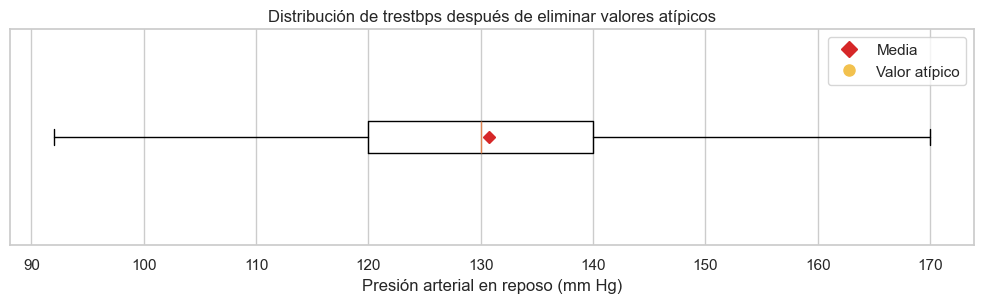

,registros_antes,registros_eliminados,registros_después
0,918,27,891


In [334]:
cardio_df_limpio = cardio_df.loc[~mascara_atipicos_trestbps].copy()

fig, eje = plt.subplots(figsize=(10, 3.2))
eje.boxplot(
    cardio_df_limpio['trestbps'],
    vert=False,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': '#d62728', 'markeredgecolor': '#d62728'},
    flierprops={'marker': 'o', 'markerfacecolor': '#f2c14e', 'markeredgecolor': '#8c6d1f', 'markersize': 4}
)
eje.set_title('Distribución de trestbps después de eliminar valores atípicos')
eje.set_xlabel('Presión arterial en reposo (mm Hg)')
eje.set_yticks([])
plt.tight_layout()
plt.legend(handles=[plt.Line2D([0], [0], color='#d62728', marker='D', linestyle='', markersize=8, label='Media'),
                    plt.Line2D([0], [0], color='#f2c14e', marker='o', linestyle='', markersize=8, label='Valor atípico')])
plt.show()

resumen_depuracion = pd.DataFrame({
    'registros_antes': [len(cardio_df)],
    'registros_eliminados': [mascara_atipicos_trestbps.sum()],
    'registros_después': [len(cardio_df_limpio)]
})

display(resumen_depuracion)

**Conclusión.** Se eliminan los **27 registros** identificados por el criterio IQR, por lo que el dataframe depurado conserva **891 pacientes**. El boxplot final ya no muestra puntos fuera de los bigotes y permite observar con mayor claridad la distribución central de la presión arterial en reposo.